# Classification Trees and Ensembles — Exercise

**Dataset:** Titanic passengers: survival from age, fare, passenger class and sex.

Read [classification_trees_ensembles_concept.ipynb](classification_trees_ensembles_concept.ipynb) first. Run cells from top to bottom. Data preparation and plotting code are provided. Replace each `None` marked with a `# TODO` comment with the expression requested above the cell. These cells are incomplete until you fill the gap. Answer interpretation questions in one or two sentences. Check your work with [classification_trees_ensembles_solution.ipynb](classification_trees_ensembles_solution.ipynb).

## Libraries and settings

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import confusion_matrix, roc_auc_score, ConfusionMatrixDisplay

## 1. Calculate Gini and a leaf probability

Replace the gap with `1 - p ** 2 - (1 - p) ** 2`. Is a 40/60 node pure? Compare the two supplied splits: which reduces Gini most? For the separate 145/125 leaf, which class is predicted?

Ersetze die Lücke durch `1 - p ** 2 - (1 - p) ** 2`. Ist eine 40/60-Knoten-Aufteilung rein? Vergleiche die beiden angegebenen Aufteilungen: Welche reduziert den Gini-Koeffizienten am stärksten? Welche Klasse wird für das separate 145/125-Blatt vorhergesagt?

In [4]:
p = 0.4
# TODO: Replace None with the expression requested above.
gini = 1 - p ** 2 - (1 - p) ** 2
print('Parent Gini:', gini)
# Split male?: 60 rows (12 survived), 40 rows (28 survived).
g_male_left = 1 - (12 / 60) ** 2 - (48 / 60) ** 2
g_male_right = 1 - (28 / 40) ** 2 - (12 / 40) ** 2
weighted_male = (60 / 100) * g_male_left + (40 / 100) * g_male_right
# Split first class?: 25 rows (15 survived), 75 rows (25 survived).
g_class_left = 1 - (15 / 25) ** 2 - (10 / 25) ** 2
g_class_right = 1 - (25 / 75) ** 2 - (50 / 75) ** 2
weighted_class = (25 / 100) * g_class_left + (75 / 100) * g_class_right
print('Gini decrease male?:', round(gini - weighted_male, 3))
print('Gini decrease first class?:', round(gini - weighted_class, 3))
leaf_probability = 145 / (145 + 125)
print('Leaf P(survived):', round(leaf_probability, 3))
print('Leaf class:', int(leaf_probability >= 0.5))

Parent Gini: 0.48
Gini decrease male?: 0.12
Gini decrease first class?: 0.027
Leaf P(survived): 0.537
Leaf class: 1


**Answer**

- Nein ein 40/60 Knoten ist nicht gar nicht rein, rein wäre 100/0 oder 0/100.
- Die Split first class Aufteilung erreicht eine höhere Reduktion des Gini Wertes.
- Die überlebenden Klasse wird vorhergesagt.

## 2. Prepare Titanic data

Data preparation is provided. What does `male` mean? Why is `stratify=y` used? Note that excluding passengers with missing age may affect representativeness.

In [5]:
titanic = pd.read_csv('../00_Data/titanic.csv')
# Fixed, simple preparation: use rows with known age and fare.
# Removing missing rows may change which passengers are represented.
titanic = titanic.dropna(subset=['Age', 'Fare']).copy()
X = titanic[['Age', 'Fare', 'Pclass']].copy()
X['male'] = (titanic['Sex'] == 'male').astype(int)
y = titanic['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.head())
print('Training rows:', len(X_train), 'Test rows:', len(X_test))

      Age     Fare  Pclass  male
619  26.0  10.5000       2     1
622  20.0  15.7417       3     1
72   21.0  73.5000       2     1
339  45.0  35.5000       1     1
513  54.0  59.4000       1     0
Training rows: 571 Test rows: 143


**Answer**

Bei Klassifikation wird `stratify=y` verwendet, damit das Klassenverhältnis ungefähr erhalten bleibt.

## 3. Train and follow a small tree

Replace the gap with `DecisionTreeClassifier(max_depth=2, random_state=42)`. Follow the rules for the two passengers supplied below. Read the class names when interpreting each leaf.

Befolgen Sie die unten angegebenen Regeln für die beiden Passagiere. Lesen Sie bei der Auswertung jedes Blattes die Klassennamen vor.

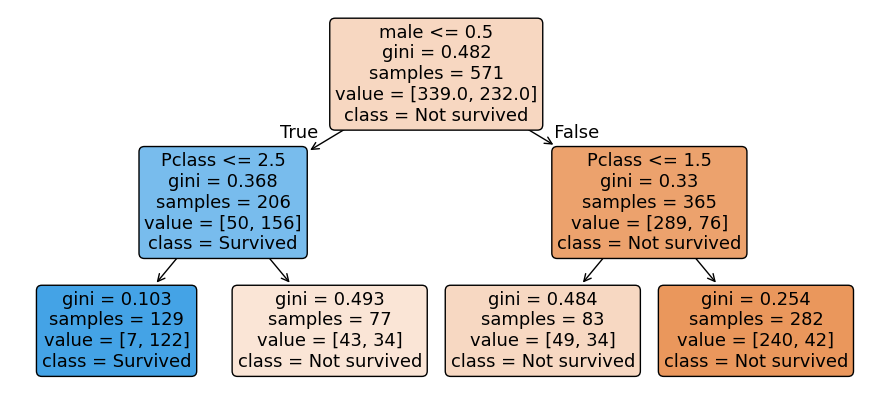

Predicted classes: [0 1]
P(survived): [0.149 0.946]


In [6]:
# TODO: Replace None with the expression requested above.
tree = DecisionTreeClassifier(max_depth=2, random_state=42)
tree.fit(X_train, y_train)
plt.figure(figsize=(11, 5))
plot_tree(tree, feature_names=list(X.columns),
          class_names=['Not survived', 'Survived'], filled=True, rounded=True)
plt.show()

new_passengers = pd.DataFrame({'Age': [30, 30], 'Fare': [10, 80],
                               'Pclass': [3, 1], 'male': [1, 0]})
print('Predicted classes:', tree.predict(new_passengers))
print('P(survived):', tree.predict_proba(new_passengers)[:, 1].round(3))

**Answer**

Die erste Person: männlich, 30 Jahre alt, 3.Klasse und 10$ bezahlt überlebt mit einer Wahrscheinlichkeit von 14.9% und die zweite Person: weiblich, 30 Jahre alt, 1.Klasse, 80$ bezahlt überlebt mit einer Wahrscheinlichkeit von 94.6%.

## 4. See the effect of pruning

The demonstration is supplied. Which setting creates fewer leaves? Why is the higher training accuracy not enough to select the tree?

In [7]:
for alpha in [0.0, 0.01]:
    pruned = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    pruned.fit(X_train, y_train)
    print('alpha:', alpha, 'leaves:', pruned.get_n_leaves(),
          # Berechnet die Modellgüte.
          'training accuracy:', round(pruned.score(X_train, y_train), 3))

alpha: 0.0 leaves: 136 training accuracy: 0.988
alpha: 0.01 leaves: 5 training accuracy: 0.8


**Answer**

- Der unbeschnittene Baum (alpha = 0) erreicht mit 136 Blättern eine Trainingsgenauigkeit von 98,8 %. Viele Blätter enthalten nur wenige Passagiere, sodass der Baum die Trainingszeilen fast auswendig gelernt hat.
- Der beschnittene Baum erreicht mit nur 5 Blättern eine Trainingsgenauigkeit von 80,0 %, was leicht zu erklären ist.
- Die 131 zusätzlichen Blätter erhöhen die Trainingsgenauigkeit um 18,8 Prozentpunkte, doch ein Großteil davon ist angepasster Rauschanteil und lässt sich nicht auf neue Passagiere übertragen.
- Die höhere Trainingsgenauigkeit reicht daher nicht aus, um den Baum auszuwählen. Die Komplexität muss anhand einer Validierung, wie beispielsweise CV, bestimmt werden.

## 5. Compare forest and boosting with CV

The models and CV are provided. Explain which ensemble averages independently built trees and which adds corrections sequentially. Compare CV AUC.

Die Modelle und die Validierungsdaten liegen vor. Erläutern Sie, welches Ensemble die unabhängig voneinander erstellten Bäume mittelt und welches Korrekturen schrittweise hinzufügt. Vergleichen Sie die AUC-Werte der Validierungsdaten.

In [8]:
forest = RandomForestClassifier(n_estimators=100, random_state=42)
boosting = GradientBoostingClassifier(n_estimators=100, max_depth=2,
                                     learning_rate=0.1, random_state=42)
for name, model in [('Forest', forest), ('Boosting', boosting)]:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    print(name, 'CV AUC:', round(scores.mean(), 3))

Forest CV AUC: 0.871
Boosting CV AUC: 0.861


**Answer**

Boosting erstellt die Korrekturen schrittweise und Forest erstellt die Bäume unabhängig voreinander. Der AUC Wert von Forest ist um 1% besser als der von Boosting.

## 6. Run the supplied search

Run this complete example. We use `max_features="sqrt"` versus `1.0` (all inputs). With our four inputs, a setting of 0.5 would also consider two inputs, exactly like sqrt; using 1.0 makes the comparison distinct. What are the chosen settings? How many setting combinations were tried? Why does the final confusion matrix use a threshold?

Führen Sie dieses vollständige Beispiel aus. Wir verwenden `max_features="sqrt"` anstelle von `1.0` (alle Eingaben). Bei unseren vier Eingaben würde eine Einstellung von 0,5 = 50% = 2 Features, ebenfalls zwei Eingaben berücksichtigen, genau wie „sqrt“; die Verwendung von 1,0 sorgt für einen deutlichen Unterschied im Vergleich. Welche Einstellungen wurden gewählt? Wie viele Einstellungskombinationen wurden ausprobiert? Warum wird in der abschließenden Verwechslungsmatrix ein Schwellenwert verwendet?

Chosen settings: {'max_features': 'sqrt', 'min_samples_leaf': 1}
Best CV AUC: 0.871
Final test AUC: 0.828
Final confusion matrix:


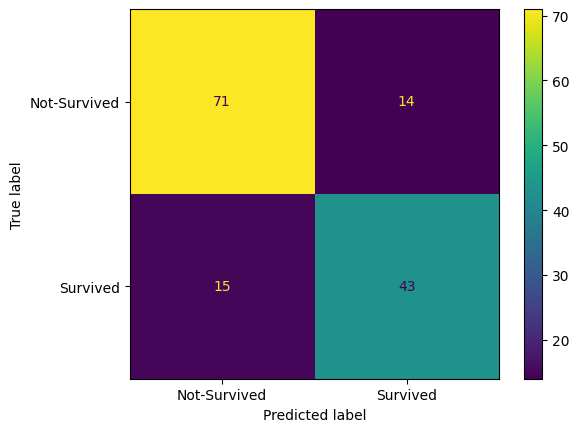

In [11]:
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=42),
    {'max_features': ['sqrt', 1.0], 'min_samples_leaf': [1, 5, 20]},
    cv=5, scoring='roc_auc')

grid.fit(X_train, y_train)
print('Chosen settings:', grid.best_params_)
print('Best CV AUC:', round(grid.best_score_, 3))

p = grid.predict_proba(X_test)[:, 1]
print('Final test AUC:', round(roc_auc_score(y_test, p), 3))
print('Final confusion matrix:')
cm = confusion_matrix(y_test, p >= 0.5, labels=[0, 1])

ConfusionMatrixDisplay(cm, display_labels=['Not-Survived', 'Survived']).plot()
plt.show()

**Answer**

Es wurde `max_features=sqrt` gewählt, also zwei Features.

### Jupyter notebook — footer info

Include this information when submitting your notebook.

In [10]:
import platform
from datetime import datetime
print(platform.platform())
print("Python:", platform.python_version())
print("Date:", datetime.now().isoformat(timespec="seconds"))

Linux-7.0.14-linuxkit-aarch64-with-glibc2.41
Python: 3.11.17
Date: 2026-10-27T19:52:16
